In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from pathlib import Path
import math
from scipy.interpolate import CubicSpline 

import tools
import my_plot as mplt

from plot_utils import set_size, set_colors, width_jcap, sci_formatter
plt.style.use('my_style.mplstyle')

In [2]:
# Plotting setup

from my_plot import set_size
import seaborn as sns
width =  508.0
widthcol = 244
plt.rcParams['font.size']=12

colors1=sns.color_palette("rocket",9) #personal fav 
colors2=sns.color_palette("mako",4) #also nice
colors3 = plt.colormaps['Spectral'].resampled(4)

colors4 = ['#c3121e', '#0348a1', '#ffb01c', '#027608', '#0193b0', '#9c5300', '#949c01', '#7104b5']
#            0sangre,   1neptune,  2pumpkin,  3clover,   4denim,    5cocoa,    6cumin,    7berry


#%matplotlib widget

In [3]:
def D(x): return x**3 * tools.I0 * (tools.G(x) * 1.6449 / (3*2.4041) - tools.nbb(x) / x) / 0.5421 

In [4]:
def read_coeffs(file):
    # Leggi il file ignorando la prima colonna
    data = np.loadtxt(file)
    # Rimuovi la prima colonna
    data = data[:, 1:]
    return data

In [5]:
def extract_Ix_from_files(folder_path, pattern="Dn_final.photon_conversion.dark-photon.dat"):
    """Extract x and Ix data from files in a folder, regular heating mode wiith no batch"""
    folder = Path(folder_path) / "PDE-non-linear"
    file_path = next(folder.glob(pattern))
    
    x = []
    Ix = []
    
    data = np.loadtxt(file_path, comments='#')  
    x.extend(data[:, 0])   # All x values from column 0
    Ix.extend(data[:, 5])  # All Ix values from column 5

    return np.array(x), np.array(Ix)

In [6]:
def extract_Ix_from_files_FH(folder_path, pattern="full_spectrum.dat_ymax15_y_bg.dat"):
    """Extract x and Ix data from files in a folder, FH module"""
    folder = Path(folder_path) / "FH" 
    file_path = next(folder.glob(pattern))
    
    x = []
    Ix = []
  
    data = np.loadtxt(file_path, comments='#')
    x.extend(data[:, 0])   # All x values from column 0
    Ix.extend(data[:, 1])  # All Ix values from column 5
    
    return np.array(x), np.array(Ix)

In [7]:
def read_Dx_from_file(file_path):
    """
    Read x and Dx data from a file for all nmax values.
    The file contain D(x) computed by cosmotherm using the mathematica coefficients and the FH module.
    D(x) varies according to the Ynmax we consider for the spectral basis, we want to compare it to the analytical function.
    """
    x = []
    Dx = [[] for _ in range(9)]  # for all nmax
    
    data = np.loadtxt(file_path, comments='#')  
    x.extend(data[:, 0])   # All x values from column 0
    for i in range(9):
        Dx[i].extend(data[:, i+1]/ 0.5421 )  # All Dx values from columns 1-9

    return np.array(x), np.array(Dx)

In [8]:
x_ct , Dx = read_Dx_from_file("D(x)_spectrum_nmax_0_15.dat")

In [9]:
x , Ix = extract_Ix_from_files("../Data/Test-code/Photon-conversion/") # [I] = Jy / sr
x_FH , Ix_FH = extract_Ix_from_files_FH("../Data/Test-code/Photon-conversion-FH/")
x_Mnum , Ix_Mnum = extract_Ix_from_files_FH("../Data/Test-code/Photon-conversion-FH-Mnum/")

In [10]:
# We read the coefficients computed by mathematica and we print it in a format useful for an overleaf table, to save time

def smart_format(val, dec=4):
    if val == 0:
        return "0"
    if abs(val) < 1e-3 or abs(val) >= 1e3:
        return np.format_float_scientific(val, precision=dec, unique=False, trim='-')
    else:
        return f"{val:.{dec}f}"

coeffs = read_coeffs("Dp_conv_coefs.dat")
nmax = [0,1,3,5,7,9,11,13,15]
for i in range(len(coeffs)):
    print(f"{nmax[i]}", end=" & ")
    row = coeffs[i]
    zero_indices = np.where(row == 0)[0]
    if len(zero_indices) > 0:
        mu_index = zero_indices[0] - 1
    else:
        mu_index = len(row) - 1
    mu = row[mu_index]
    print(f"{mu:.3f}", end=" & ")
    for j in range(len(row)):
        if j != mu_index :
            val = smart_format(row[j], dec=3)
            
            #print(f"{val}", end=" & " if j < len(row) - 1 else "\\\ \n" )

0 & 0.838 & 1 & 0.895 & 3 & 0.940 & 5 & 0.961 & 7 & 0.972 & 9 & 0.980 & 11 & 0.984 & 13 & 0.987 & 15 & 0.987 & 

In [11]:

# Find common frequency range
xmin = max(x.min(), x_FH.min(), x_Mnum.min())
xmax = min(x.max(), x_FH.max(), x_Mnum.max())

# Mask arrays to common range
mask_x = (x >= xmin) & (x <= xmax)
mask_x_FH = (x_FH >= xmin) & (x_FH <= xmax)
mask_x_Mnum = (x_Mnum >= xmin) & (x_Mnum <= xmax)
x_common = np.linspace(xmin, xmax, 500)

# Cubic spline fits (exact interpolation for clean simulation data)
spline_Ix = CubicSpline(x[mask_x], Ix[mask_x])
spline_Ix_FH = CubicSpline(x_FH[mask_x_FH], Ix_FH[mask_x_FH])
spline_Ix_Mnum = CubicSpline(x_Mnum[mask_x_Mnum], Ix_Mnum[mask_x_Mnum])

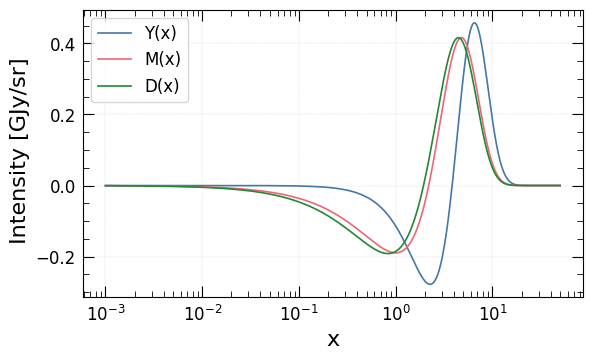

In [12]:
colors = set_colors(3, palette="tol:bright")

# Plot Analytical Spectra
fig, ax1 = plt.subplots(1, 1, figsize=set_size(width_jcap))

ax1.plot(x_ct, tools.Y(x_ct) / 1e9, label="Y(x)", color=colors[0], linestyle="-")
ax1.plot(x_ct, tools.M(x_ct) / 1e9, label="M(x)", color=colors[1], linestyle="-")
ax1.plot(x_ct, D(x_ct) / 1e9, label="D(x)", color=colors[2], linestyle="-")

ax1.set_xscale('log')

ax1.set_ylabel(" Intensity [GJy/sr]")
ax1.set_xlabel("x")

plt.legend(loc='upper left')
plt.savefig('outputs/DYM.pdf', dpi=300, bbox_inches="tight")
plt.show()

In [13]:
len(Dx)

9

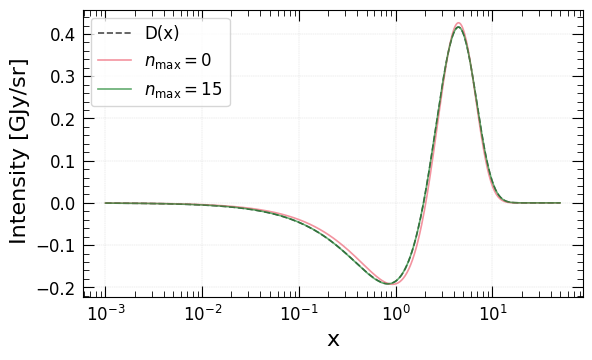

In [14]:
# Plot Analytical Spectra
fig, ax1 = plt.subplots(1, 1, figsize=set_size(width_jcap))

ax1.plot(x_ct, D(x_ct) / 1e9, label="D(x)", color="black", alpha=0.7, linewidth=1.2, linestyle="--")

ax1.plot(x_ct, Dx[0]/1e9, alpha=0.7, label="$n_{\\rm max} = 0$", color=colors[1], linewidth=1.2, linestyle="-")
ax1.plot(x_ct, Dx[8]/1e9, alpha=0.7, label="$n_{\\rm max} = 15$", color=colors[2], linewidth=1.2, linestyle="-")


ax1.set_xscale('log')

ax1.set_ylabel(" Intensity [GJy/sr]")
ax1.set_xlabel("x")


plt.legend(loc='upper left')
#plt.savefig('outputs/Dx.pdf', dpi=300, bbox_inches="tight")
plt.show()

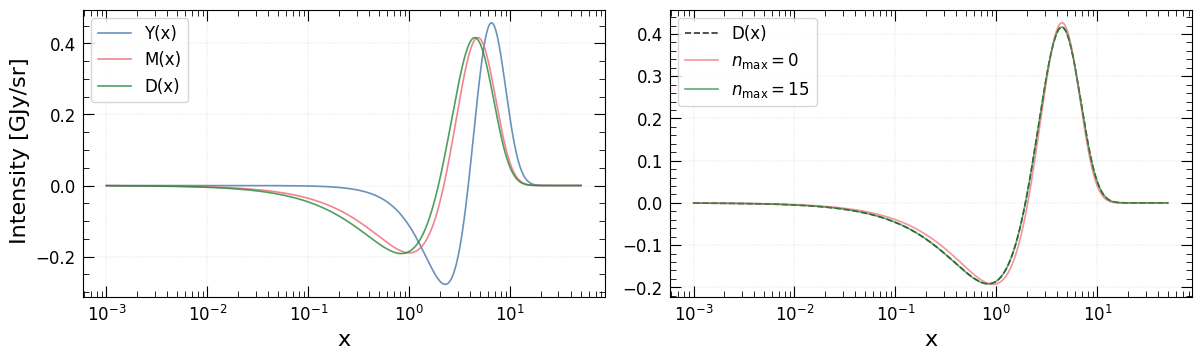

In [15]:
# Plot Analytical Spectra
fig, ax1 = plt.subplots(1, 2, figsize=set_size(width_jcap*2, 1, (1,2)))

ax1[0].plot(x_ct, tools.Y(x_ct) / 1e9, label="Y(x)", color=colors[0], alpha=0.8, linestyle="-")
ax1[0].plot(x_ct, tools.M(x_ct) / 1e9, label="M(x)", color=colors[1], alpha=0.8, linestyle="-")
ax1[0].plot(x_ct, D(x_ct) / 1e9, label="D(x)", color=colors[2], alpha=0.8, linestyle="-")
#ax1[1].set_yscale('log')

ax1[1].plot(x_ct, D(x_ct) / 1e9, label="D(x)", color="black", alpha=0.8, linestyle="--")
ax1[1].plot(x_ct, Dx[0]/1e9, alpha=0.7, label="$n_{\\rm max} = 0$", color=colors[1], linewidth=1.2, linestyle="-")
ax1[1].plot(x_ct, Dx[8]/1e9, alpha=0.7, label="$n_{\\rm max} = 15$", color=colors[2], linewidth=1.2, linestyle="-")


ax1[0].set_xscale('log')
ax1[1].set_xscale('log')

ax1[0].set_ylabel(" Intensity [GJy/sr]")
ax1[0].set_xlabel("x")
ax1[1].set_xlabel("x")


ax1[0].legend(loc='upper left')
ax1[1].legend(loc='upper left')

plt.savefig('outputs/Dx.pdf', dpi=300, bbox_inches="tight")
plt.show()

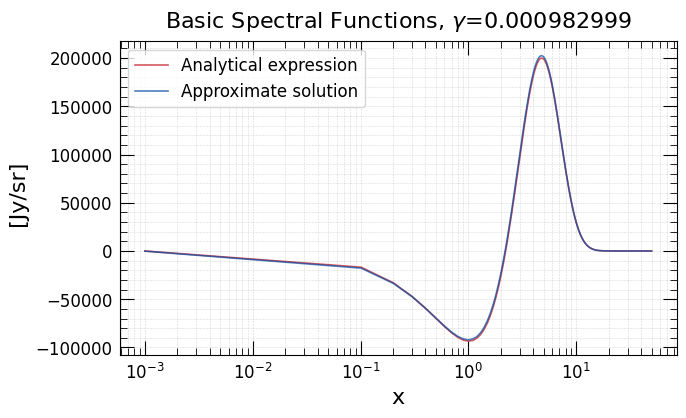

In [16]:

# Plot Analytical Spectra
gamma = 0.000982999
fig, ax1 = plt.subplots(1, 1, figsize=set_size(width))

ax1.plot(x_common, spline_Ix(x_common), label="Analytical expression", color=colors4[0], alpha=0.7, linestyle="-")
ax1.plot(x_common, spline_Ix_FH(x_common), label="Approximate solution", color=colors4[1], alpha=0.7, linestyle="-")
#ax1.plot(x_common, spline_Ix_Mnum(x_common), label="Mnum", color=colors4[3], alpha=0.7, linestyle="-")
#ax1.plot(x_common, 0.5421 * D(x_common) * gamma, label="D(x)*$\\gamma$", color=colors4[2], alpha=0.7, linestyle="-")


ax1.set_xscale('log')
#ax1.set_yscale('log')
#ax1.set_ylim(top=6)
#ax1.set_xlim([1e+0, 5e+3])

plt.minorticks_on()
plt.tick_params(direction='in',right=True, top=True)
plt.tick_params(labelsize=12)
plt.tick_params(labelbottom=True, labeltop=False, labelright=False, labelleft=True)
plt.tick_params(direction='in',which='minor', length=5, bottom=True, top=True, left=True, right=True)
plt.tick_params(direction='in',which='major', length=10, bottom=True, top=True, left=True, right=True)

ax1.set_ylabel(" [Jy/sr]")
ax1.set_xlabel("x")
ax1.set_title("Basic Spectral Functions, $\\gamma$="+str(gamma))
ax1.grid(True, which='both', linestyle='--', linewidth=0.4)
plt.legend(loc='upper left')
#plt.savefig('outputs/H0_evolution.pdf', dpi=300, bbox_inches="tight")
plt.show()

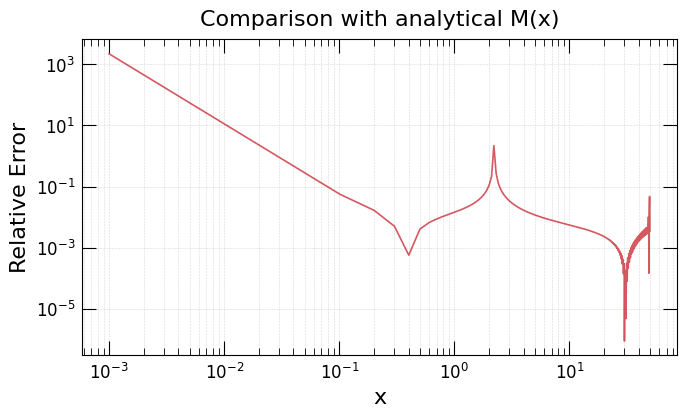

In [17]:
# Plot Relative Difference: FH vs Heating mode 10
gamma = 0.000982999
fig, ax1 = plt.subplots(1, 1, figsize=set_size(width))

ax1.plot(x_common, np.abs(spline_Ix(x_common) - spline_Ix_FH(x_common)) / np.abs(spline_Ix(x_common)),  color=colors4[0], alpha=0.7, linestyle="-")

ax1.set_xscale('log')
ax1.set_yscale('log')
ax1.set_ylabel("Relative Error")
ax1.set_xlabel("x")
ax1.set_title("Comparison with analytical M(x)")
ax1.grid(True, which='both', linestyle='--', linewidth=0.4)
#ax1.legend(loc='upper left')

plt.minorticks_on()
plt.tick_params(direction='in',right=True, top=True, labelsize=12)
plt.tick_params(labelbottom=True, labeltop=False, labelright=False, labelleft=True)
plt.tick_params(direction='in',which='minor', length=5, bottom=True, top=True, left=True, right=True)
plt.tick_params(direction='in',which='major', length=10, bottom=True, top=True, left=True, right=True)

#plt.savefig('outputs/relative_difference_FH.pdf', dpi=300, bbox_inches="tight")
plt.show()


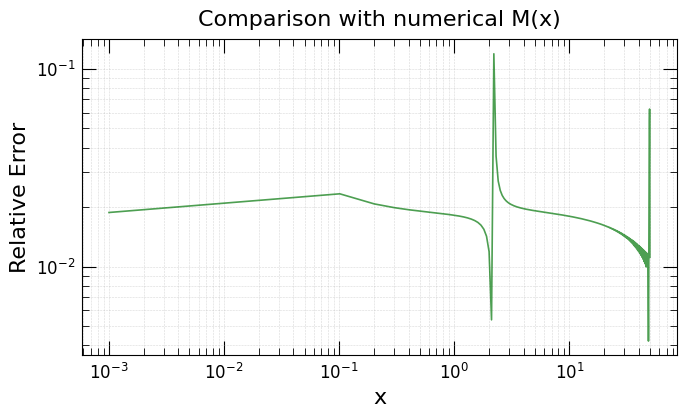

In [18]:
# Plot Relative Difference: Mnum vs Heating mode 10
gamma = 0.000982999
fig, ax1 = plt.subplots(1, 1, figsize=set_size(width))

ax1.plot(x_common, np.abs(spline_Ix(x_common) - spline_Ix_Mnum(x_common)) / np.abs(spline_Ix(x_common)),  color=colors4[3], alpha=0.7, linestyle="-")

ax1.set_xscale('log')
ax1.set_yscale('log')
ax1.set_ylabel("Relative Error")
ax1.set_xlabel("x")
ax1.set_title("Comparison with numerical M(x)")
ax1.grid(True, which='both', linestyle='--', linewidth=0.4)
#ax1.legend(loc='upper left')

plt.minorticks_on()
plt.tick_params(direction='in',right=True, top=True, labelsize=12)
plt.tick_params(labelbottom=True, labeltop=False, labelright=False, labelleft=True)
plt.tick_params(direction='in',which='minor', length=5, bottom=True, top=True, left=True, right=True)
plt.tick_params(direction='in',which='major', length=10, bottom=True, top=True, left=True, right=True)

#plt.savefig('outputs/relative_difference_Mnum.pdf', dpi=300, bbox_inches="tight")
plt.show()


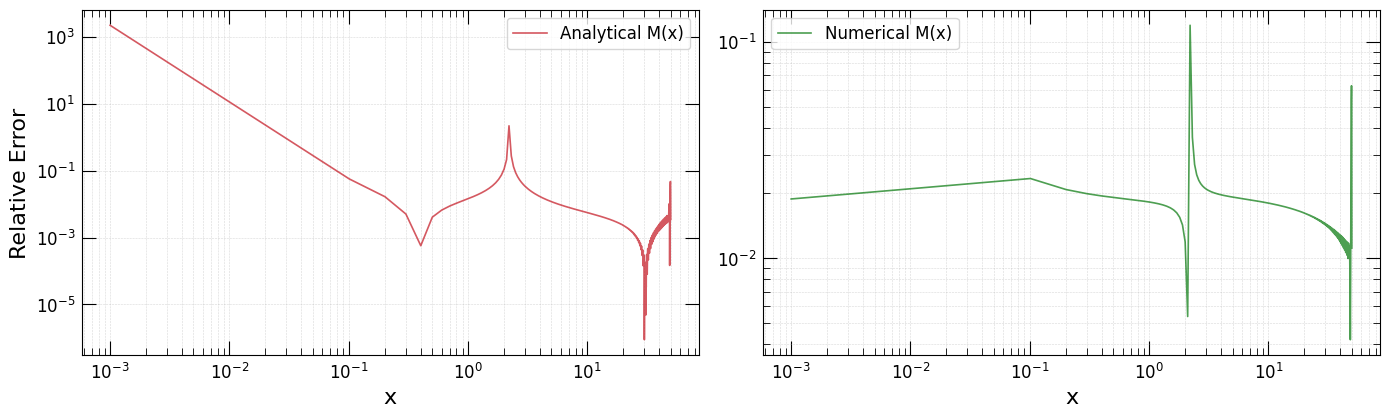

In [19]:
# Plot Relative Differences (Combined)
gamma = 0.000982999
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(set_size(width)[0]*2, set_size(width)[1]*1))

# Top plot: FH vs Heating mode 10
ax1.plot(x_common, np.abs(spline_Ix(x_common) - spline_Ix_FH(x_common)) / np.abs(spline_Ix(x_common)), label="Analytical M(x)", color=colors4[0], alpha=0.7, linestyle="-")

ax1.set_xscale('log')
ax1.set_yscale('log')
ax1.set_ylabel("Relative Error")
ax1.set_xlabel("x")
#ax1.set_title("Relative Difference: Analytical M vs Heating mode 10")
ax1.grid(True, which='both', linestyle='--', linewidth=0.4)
ax1.legend()
ax1.minorticks_on()
ax1.tick_params(direction='in',right=True, top=True, labelsize=12)
ax1.tick_params(labelbottom=True, labeltop=False, labelright=False, labelleft=True)
ax1.tick_params(direction='in',which='minor', length=5, bottom=True, top=True, left=True, right=True)
ax1.tick_params(direction='in',which='major', length=10, bottom=True, top=True, left=True, right=True)

# Bottom plot: Mnum vs Heating mode 10
ax2.plot(x_common, np.abs(spline_Ix(x_common) - spline_Ix_Mnum(x_common)) / np.abs(spline_Ix(x_common)), label="Numerical M(x)", color=colors4[3], alpha=0.7, linestyle="-")

ax2.set_xscale('log')
#ax2.set_ylabel("Relative Error")
ax2.set_xlabel("x")
#ax2.set_title("Relative Difference: Numerical M vs Heating mode 10")
ax2.set_yscale('log')
ax2.grid(True, which='both', linestyle='--', linewidth=0.4)
ax2.legend()
ax2.minorticks_on()
ax2.tick_params(direction='in',right=True, top=True, labelsize=12)
ax2.tick_params(labelbottom=True, labeltop=False, labelright=False, labelleft=True)
ax2.tick_params(direction='in',which='minor', length=5, bottom=True, top=True, left=True, right=True)
ax2.tick_params(direction='in',which='major', length=10, bottom=True, top=True, left=True, right=True)

plt.tight_layout()
plt.savefig('outputs/relative_differences.pdf', dpi=300, bbox_inches="tight")
plt.show()
